# Capítulo 5 · Actividad: ¿cuánto consume este auto?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/02_actividad_mpg_regresion.ipynb)

Entrena una **regresión** que prediga el rendimiento de un auto en **millas por galón** (`mpg`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

| Variable | Significado |
|---|---|
| `mpg` | **Target**: millas por galón (más alto = consume menos) |
| `cylinders` | Número de cilindros |
| `displacement` | Cilindrada del motor (pulgadas cúbicas) |
| `horsepower` | Potencia (caballos de fuerza) |
| `weight` | Peso (libras) |
| `acceleration` | Segundos para ir de 0 a 60 mph |
| `model_year` | Año del modelo (70 = 1970) |
| `origin` | Región de origen: `usa`, `europe` o `japan` |
| `name` | Nombre del auto |

Como mínimo, tu notebook debe incluir:

- Un **modelo lineal base**: coeficientes, métricas de error y $R^2$.
- Los mismos modelos que vimos en clase: regresión simple, lineal múltiple, Ridge, Lasso, polinomial y RANSAC.
- Una **tabla final** comparando los modelos con validación cruzada y test, y tus **conclusiones**: ¿qué modelo elegirías y por qué?

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.linear_model import Lasso, LinearRegression, RANSACRegressor, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [34]:
# Tu código 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [35]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [36]:
df["cylinders"].value_counts()

cylinders
4    204
8    103
6     84
3      4
5      3
Name: count, dtype: int64

In [37]:
df["model_year"].value_counts()

model_year
73    40
78    36
76    34
82    31
75    30
70    29
79    29
80    29
81    29
71    28
72    28
77    28
74    27
Name: count, dtype: int64

In [38]:
df["origin"].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

In [39]:
df["name"].value_counts()

name
ford pinto          6
ford maverick       5
amc matador         5
toyota corolla      5
chevrolet impala    4
                   ..
ford mustang gl     1
vw pickup           1
dodge rampage       1
ford ranger         1
chevy s-10          1
Name: count, Length: 305, dtype: int64

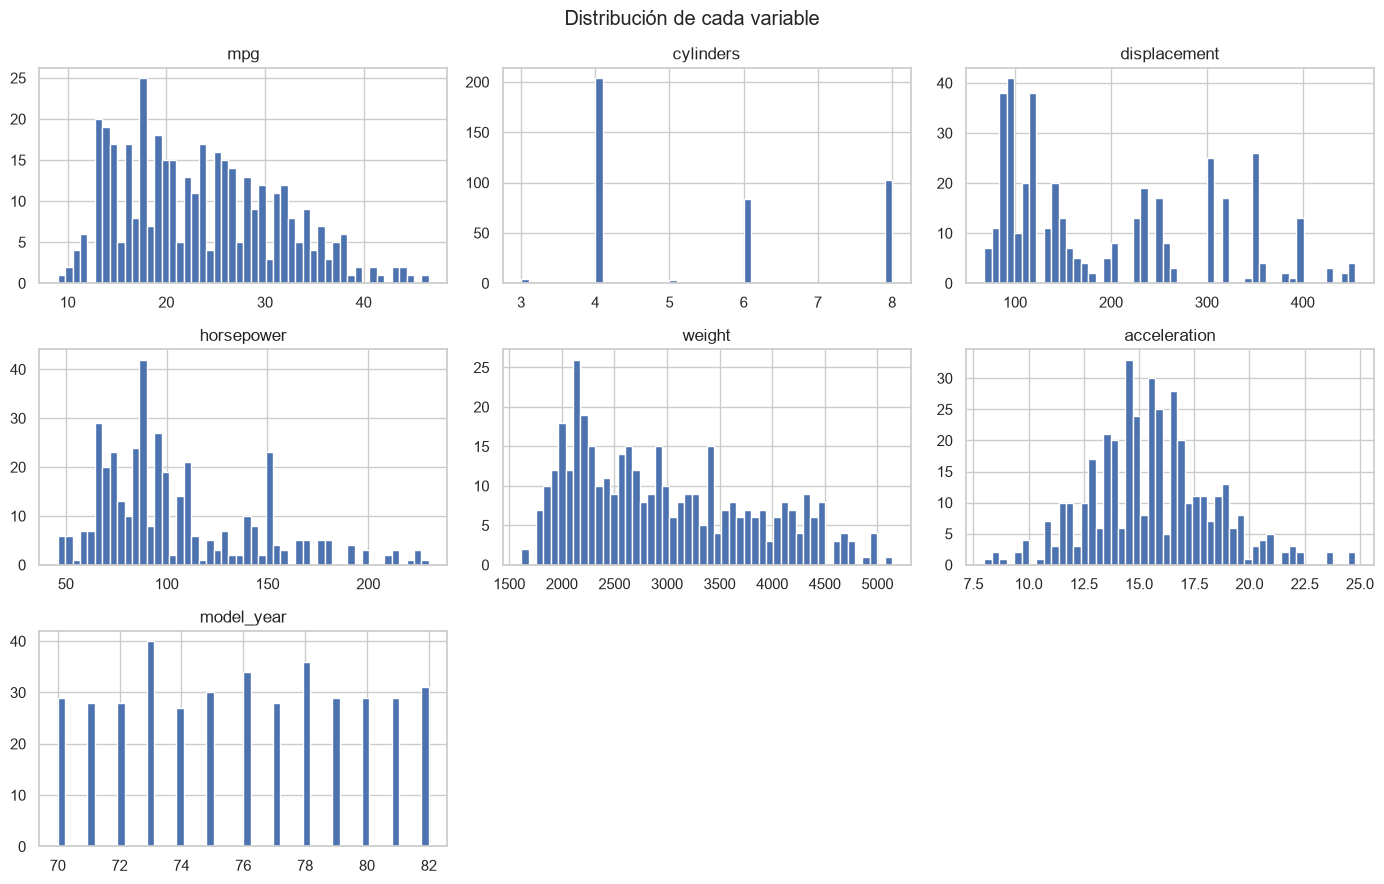

In [40]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

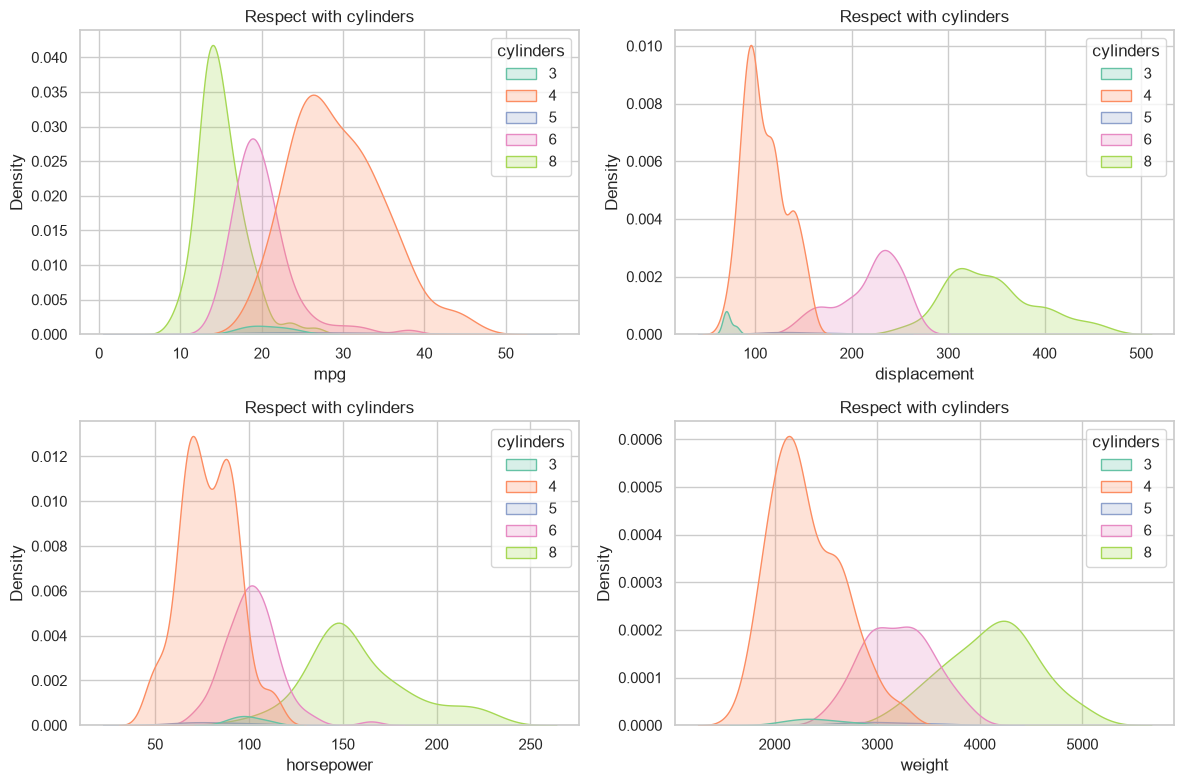

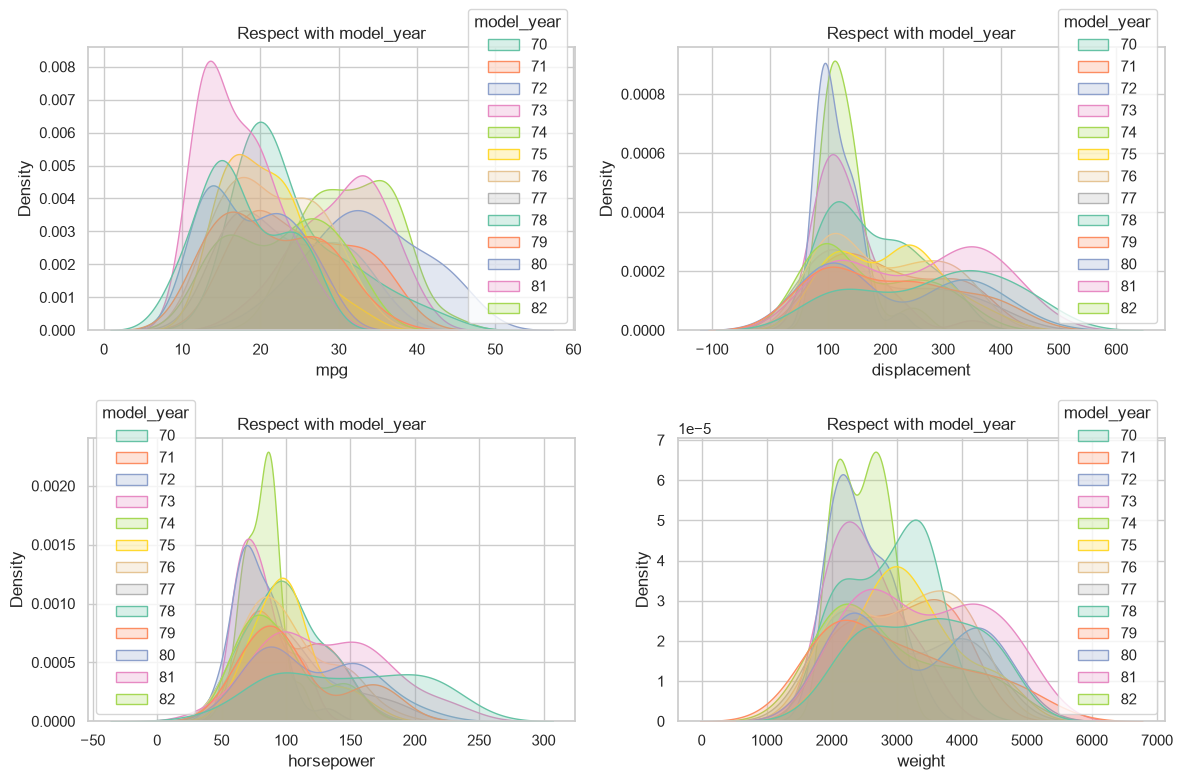

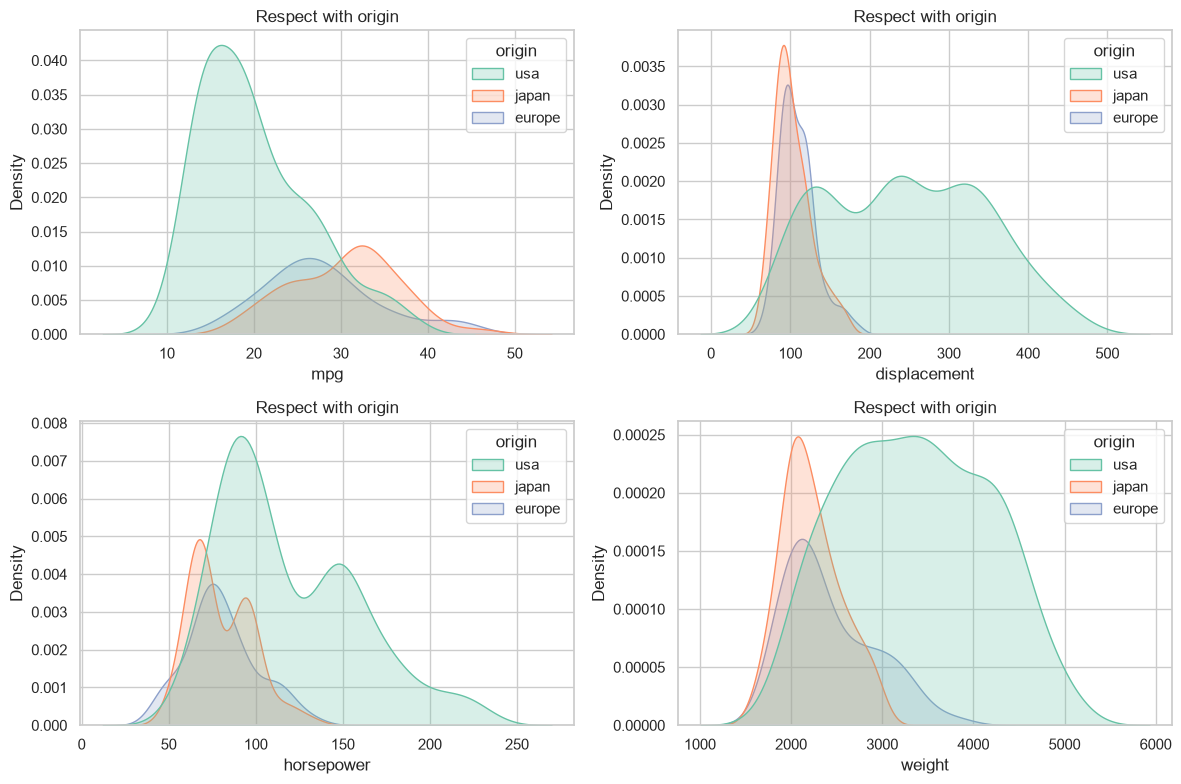

In [41]:
variables = ["mpg","displacement","horsepower","weight","acceleration"]
variables_c = ["cylinders","model_year","origin"]

for var in variables_c:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for variable, ax in zip(variables, axes.flat):
        sns.kdeplot(data=df, x=variable, hue=var, fill=True, palette="Set2", ax=ax)
        ax.set_title(f"Respect with {var}")
    plt.tight_layout()
    plt.show()

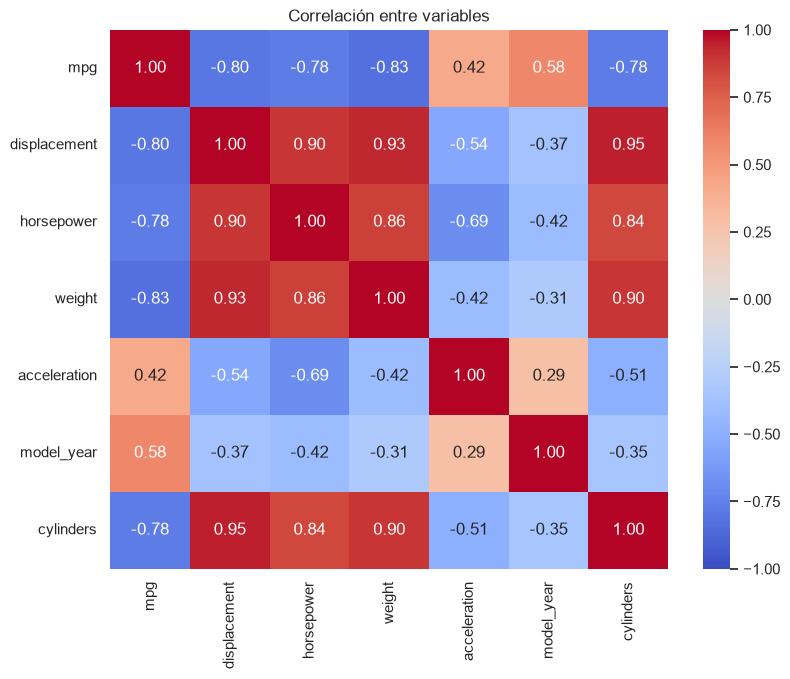

In [42]:
correlaciones = df[["mpg","displacement","horsepower","weight","acceleration","model_year","cylinders"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

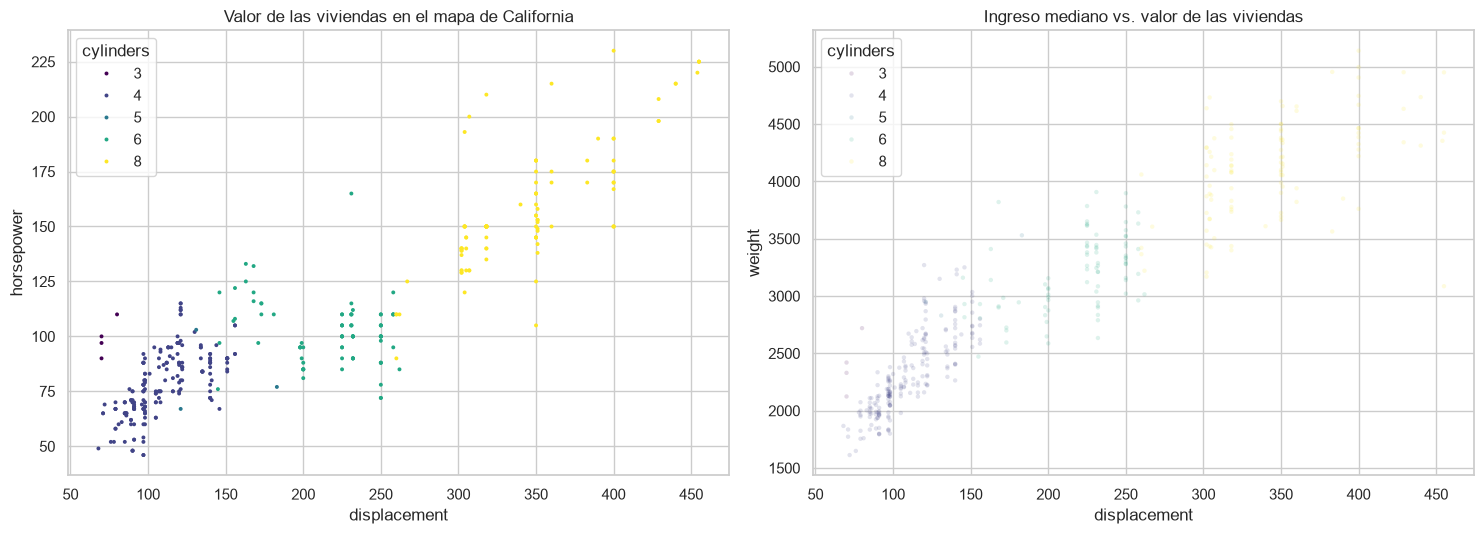

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x="displacement", y="horsepower",hue="cylinders", palette="viridis",
                s=8, linewidth=0, ax=axes[0])
axes[0].set_title("Valor de las viviendas en el mapa de California")

sns.scatterplot(data=df, x="displacement", y="weight", hue="cylinders", palette="viridis", alpha=0.15, s=10, linewidth=0, ax=axes[1])
axes[1].set_title("Ingreso mediano vs. valor de las viviendas")
plt.tight_layout()
plt.show()

In [44]:
print("Valores nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Filas duplicadas: 0


In [45]:
df[df.isna().any(axis=1)]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


In [46]:
#df = df.drop(df[df["cylinders"] == 3].index)
#df = df.drop(df[df["cylinders"] == 5].index)
df["cylinders"].value_counts()

cylinders
4    204
8    103
6     84
3      4
5      3
Name: count, dtype: int64

In [47]:
df = df.drop(columns=["cylinders","weight"])

In [48]:
variantes = {
    "chevy": "chevrolet",
    "chevroelt": "chevrolet",
    "maxda": "mazda",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
    "mercedes": "mercedes-benz",
}

df["marca"] = df["name"].str.split().str[0]
df["marca"] = df["marca"].replace(variantes)
df =  df.drop(columns=["name","marca"])
#df["marca"].value_counts()

In [49]:
X = df.drop(columns="mpg")
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Validación cruzada que usaremos durante toda la clase
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (318, 5) | Test: (80, 5)


In [50]:
numericas = ["displacement","horsepower", "model_year", "acceleration"]
nominales = ["origin"]

# Un solo paso: se puede poner directamente, sin Pipeline
# Varios pasos en orden: se encadenan con un Pipeline
pipeline_num = Pipeline([
    ("impt", SimpleImputer(strategy="median"))
])

pipeline_nom = Pipeline([("imput",SimpleImputer(strategy="most_frequent")),
    ("OneHot",OneHotEncoder(handle_unknown="ignore",sparse_output=False, drop="if_binary"))
    ])

preprocesador = ColumnTransformer([
    ("num", pipeline_num, numericas),
    ("nom", pipeline_nom, nominales),   # garaje: una sola columna
])


In [51]:
X_train_proc = preprocesador.fit_transform(X_train)
X_test_proc = preprocesador.transform(X_test)

In [52]:
q1 = X_train_proc.quantile(0.25)
q3 = X_train_proc.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_outlier = (X_train_proc < limite_inferior) | (X_train_proc > limite_superior)
es_outlier.sum()

num__displacement      0
num__horsepower       11
num__model_year        0
num__acceleration      5
nom__origin_europe    56
nom__origin_japan     66
nom__origin_usa        0
dtype: int64

In [53]:
X_train_antes = X_train_proc.copy()   # solo para comparar en la gráfica

X_train_proc = X_train_proc.clip(lower=limite_inferior, upper=limite_superior, axis=1)
X_test_proc = X_test_proc.clip(lower=limite_inferior, upper=limite_superior, axis=1)

In [54]:
modelo_simple = LinearRegression()
modelo_simple.fit(X_train_proc, y_train)   # doble corchete: X debe ser una tabla, no una columna

beta_0 = modelo_simple.intercept_
beta_1 = modelo_simple.coef_[0]
print(f"Intercepto  β0 = {beta_0:.3f}")
print(f"Pendiente   β1 = {beta_1:.3f}")

pred_simple = modelo_simple.predict(X_test_proc)
print(f"R² en test:   {r2_score(y_test, pred_simple):.3f}")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_simple):.3f}")

Intercepto  β0 = -4.617
Pendiente   β1 = -0.017
R² en test:   0.807
RMSE en test: 3.222


In [55]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression()),
])

modelo_lineal.fit(X_train_proc,y_train)

pred_lineal = modelo_lineal.predict(X_test_proc)
print(f"R² en test:   {r2_score(y_test, pred_lineal):.3f}   (regresión simple: {r2_score(y_test, pred_simple):.3f})")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_lineal):.3f}   (regresión simple: {root_mean_squared_error(y_test, pred_simple):.3f})")


R² en test:   0.807   (regresión simple: 0.807)
RMSE en test: 3.222   (regresión simple: 3.222)


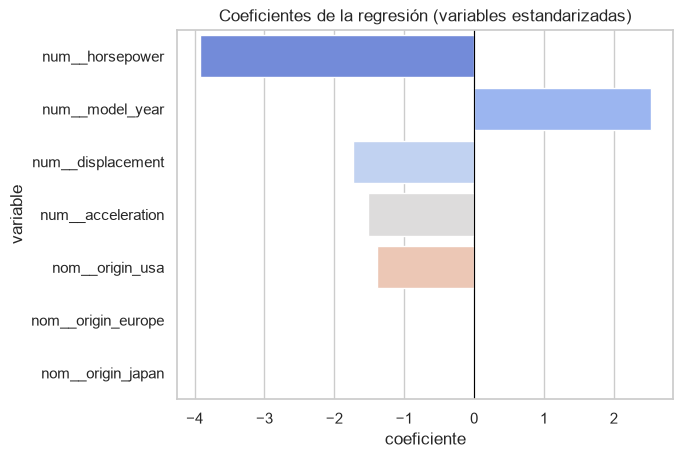

,variable,coeficiente
1,num__horsepower,-3.923
2,num__model_year,2.530
0,num__displacement,-1.736
3,num__acceleration,-1.520
6,nom__origin_usa,-1.395
4,nom__origin_europe,0.000
5,nom__origin_japan,0.000


In [56]:
coeficientes = pd.DataFrame({
    "variable": X_train_proc.columns,
    "coeficiente": modelo_lineal.named_steps["regresion"].coef_,
}).sort_values("coeficiente", key=abs, ascending=False)

ax = sns.barplot(data=coeficientes, x="coeficiente", y="variable", hue="variable", palette="coolwarm")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes de la regresión (variables estandarizadas)")
plt.show()

coeficientes.round(3)

In [57]:
def metricas_regresion(y_real, y_pred, n_variables):
    "Métricas principales de una regresión."
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    return {
        "MSE": mean_squared_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "MAPE": mean_absolute_percentage_error(y_real, y_pred),
        "R²": r2,
        "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_variables - 1),
        "Correlación(y, ŷ)": np.corrcoef(y_real, y_pred)[0, 1],
    }


pd.DataFrame({
    "Simple (MedInc)": metricas_regresion(y_test, pred_simple, n_variables=1),
    "Múltiple (8 variables)": metricas_regresion(y_test, pred_lineal, n_variables=8),
}).round(3)

,Simple (MedInc),Múltiple (8 variables)
MSE,10.383,10.383
RMSE,3.222,3.222
MAE,2.478,2.478
MAPE,0.121,0.121
R²,0.807,0.807
R² ajustado,0.804,0.785
"Correlación(y, ŷ)",0.906,0.906


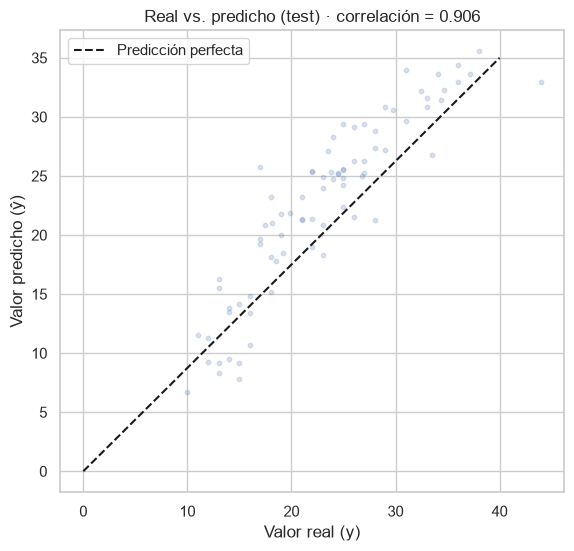

In [58]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred_lineal, alpha=0.2, s=10)
ax.plot([0, 40], [0, 35], "k--", label="Predicción perfecta")
ax.set_xlabel("Valor real (y)")
ax.set_ylabel("Valor predicho (ŷ)")
ax.set_title(f"Real vs. predicho (test) · correlación = {np.corrcoef(y_test, pred_lineal)[0, 1]:.3f}")
ax.legend()
plt.show()

In [59]:
modelos = {
    "Simple (MedInc)": LinearRegression(),
    "Lineal múltiple": modelo_lineal,
    "Ridge": Pipeline([("escalador", StandardScaler()), ("regresion", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("escalador", StandardScaler()), ("regresion", Lasso(alpha=0.01))]),
    "Polinomial (grado 2)": Pipeline([
        ("escalador", StandardScaler()),
        ("poli", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalador_poli", StandardScaler()),
        ("regresion", LinearRegression()),
    ]),
    "RANSAC": Pipeline([("escalador", StandardScaler()),
                        ("regresion", RANSACRegressor(LinearRegression(), random_state=SEED))]),
}

filas = []
predicciones = {}
for nombre, modelo in modelos.items():
    cv_res = cross_validate(modelo, X_train_proc, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", return_train_score=True)
    modelo.fit(X_train_proc, y_train)
    pred = modelo.predict(X_test_proc)
    fila = {"modelo": nombre,
            "RMSE train (CV)": -cv_res["train_score"].mean(),
            "RMSE validación (CV)": -cv_res["test_score"].mean(),
            "RMSE validación (desv.)": cv_res["test_score"].std()}
    fila.update({f"{metrica} test": valor
                 for metrica, valor in metricas_regresion(y_test, pred, n_variables=len(X_train_proc)).items()})
    filas.append(fila)
    predicciones[nombre] = pred

reporte = pd.DataFrame(filas).set_index("modelo")
reporte.drop(columns=["MSE test", "R² ajustado test"]).round(3)

,RMSE train (CV),RMSE validación (CV),RMSE validación (desv.),RMSE test,MAE test,MAPE test,R² test,"Correlación(y, ŷ) test"
modelo,,,,,,,,
Simple (MedInc),3.724,3.782,0.273,3.222,2.478,0.121,0.807,0.906
Lineal múltiple,3.724,3.782,0.273,3.222,2.478,0.121,0.807,0.906
Ridge,3.724,3.781,0.269,3.220,2.476,0.120,0.807,0.906
Lasso,3.724,3.782,0.271,3.219,2.476,0.120,0.807,0.906
Polinomial (grado 2),2.825,3.164,0.254,2.238,1.678,0.077,0.907,0.953
RANSAC,3.971,3.968,0.106,3.489,2.708,0.136,0.774,0.902


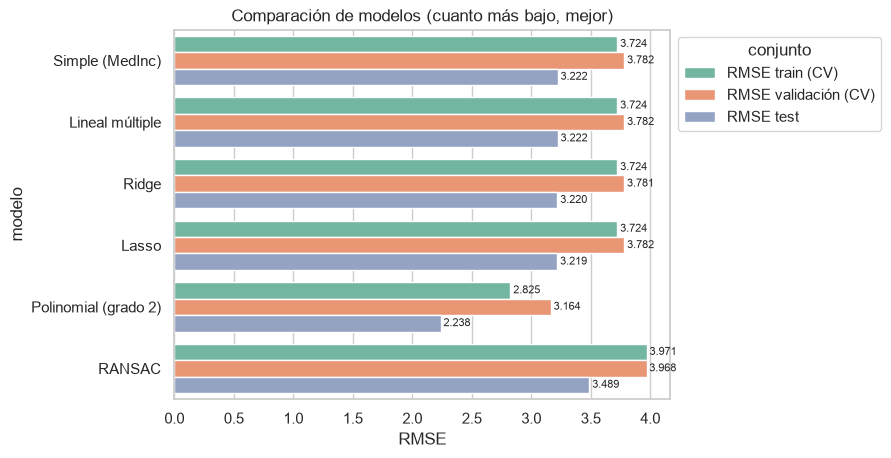

In [60]:
reporte_largo = (reporte[["RMSE train (CV)", "RMSE validación (CV)", "RMSE test"]]
                 .reset_index()
                 .melt(id_vars="modelo", var_name="conjunto", value_name="RMSE"))

ax = sns.barplot(data=reporte_largo, x="RMSE", y="modelo", hue="conjunto", palette="Set2")
ax.set_title("Comparación de modelos (cuanto más bajo, mejor)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", fontsize=8, padding=2)
plt.show()

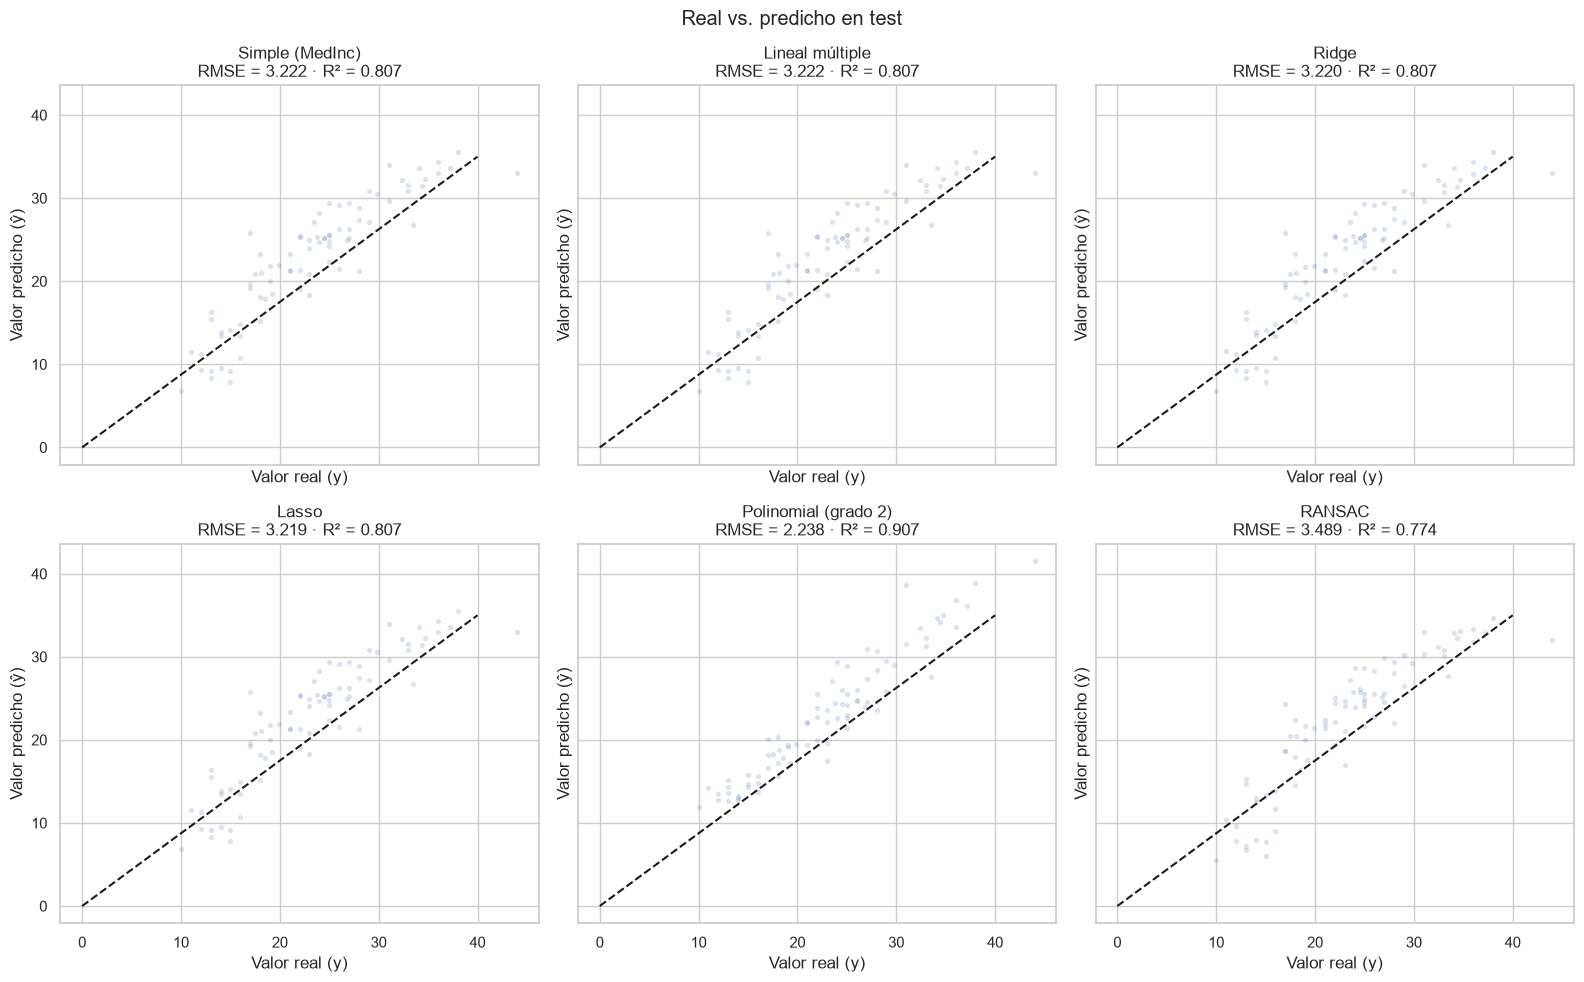

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
for (nombre, pred), ax in zip(predicciones.items(), axes.flat):
    ax.scatter(y_test, pred, alpha=0.15, s=8)
    ax.plot([0, 40], [0, 35], "k--")
    ax.set_title(f"{nombre}\nRMSE = {root_mean_squared_error(y_test, pred):.3f} · R² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Valor real (y)")
    ax.set_ylabel("Valor predicho (ŷ)")
fig.suptitle("Real vs. predicho en test")
plt.tight_layout()
plt.show()